   
WarmUp
=======

Trend-Seasonal
=======

Differencing
===========

**Times series course**  
IMT Mines ALES  
2IA



## Shampoo sales

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf
from pmdarima.arima import ndiffs

The `shampoo_sales.csv` time series describes monthly sales of a certain shampoo over a 3-year period, from the beginning of 1995. 

Read the `shampoo_sales.csv` time series with the appropriate time index, and plot it.

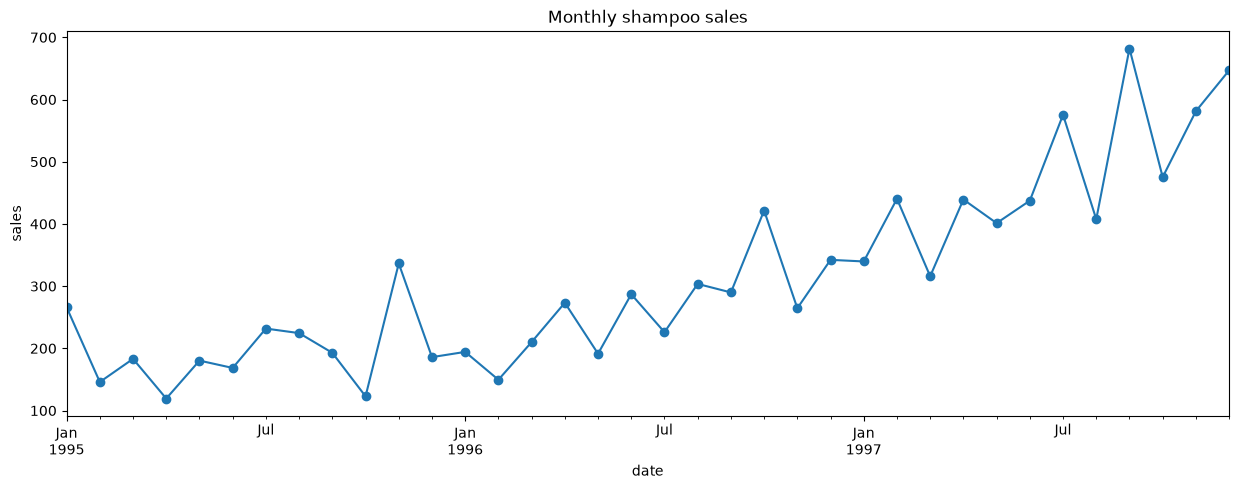

In [21]:
df = pd.read_csv(
    "../data/shampoo_sales.csv",
    usecols=["Sales"],          # the header row is used; drop the non-date "Month" column
)
df.columns = ["sales"]

# Monthly index starting January 1995; periods=len(df) keeps it aligned with the data (36 months)
df.index = pd.date_range(start="1995-01", periods=len(df), freq="MS")
df.index.name = "date"

sales = df["sales"]

fig, ax = plt.subplots(figsize=(15, 5))
sales.plot(ax=ax, marker="o")
ax.set_ylabel("sales")
ax.set_title("Monthly shampoo sales")
plt.show()

In [22]:
by_year = sales.groupby(sales.index.year)
pd.DataFrame({
    "mean": by_year.mean(),
    "std": by_year.std(),
    "cv": by_year.std() / by_year.mean(),
})

,mean,std,cv
date,,,
1995,196.458333,61.606913,0.313588
1996,262.791667,74.708007,0.284286
1997,478.550000,117.212383,0.244932


Test a seasonal decomposition. Does the decomposition model appear to be additive or multiplicative?

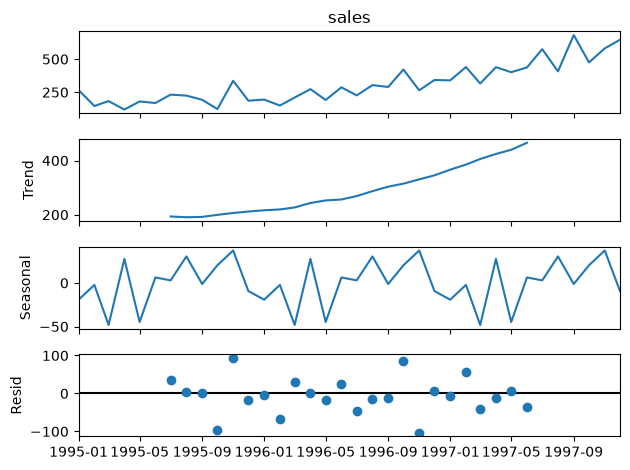

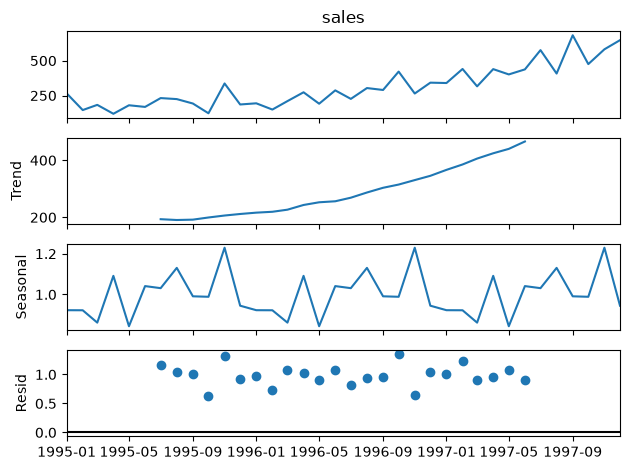

In [23]:
dec_add = seasonal_decompose(sales, model="additive", period=12)
dec_mul = seasonal_decompose(sales, model="multiplicative", period=12)
dec_add.plot(); dec_mul.plot(); plt.show()

**Answer.** Neither model is clearly better. The seasonal component (about ±45 in the additive model, 0.85–1.23 in the multiplicative one) has the same order of magnitude as the residuals, has no recognizable yearly shape, and each monthly factor is estimated from only 2 values (3 years of data minus the 6 months lost at each end by the moving average). The apparent seasonality is therefore most likely noise.

The dominant feature is a non-linear, accelerating upward trend. The yearly standard deviation grows with the level (62 → 117) while the coefficient of variation stays roughly stable (0.31 → 0.24). This suggests mildly multiplicative noise, which a log transform could stabilize.

Create a function `difference` that takes as parameter the time series and the interval of differencing, and return the differenced time series.

In [24]:
def difference(series: pd.Series, lag: int = 1) -> pd.Series:
    """Compute the lagged difference of a time series.

    Each value is replaced by ``y(t) - y(t - lag)``. A lag of 1 removes a
    linear trend; a lag equal to the seasonal period (e.g. 12 for monthly
    data) removes a stable seasonal pattern.

    Args:
        series: Time series to difference, indexed by time.
        lag: Number of periods between the two values being subtracted.
            Must be a positive integer. Defaults to 1.

    Returns:
        The differenced series, with the same index as ``series``. The first
        ``lag`` values are NaN because they have no earlier value to subtract.

    Raises:
        ValueError: If ``lag`` is not a positive integer.
    """
    if lag < 1:
        raise ValueError(f"lag must be a positive integer, got {lag}")
    return series - series.shift(lag)

Try the difference function to remove trend. Create a new dataframe from this "detrended" series.

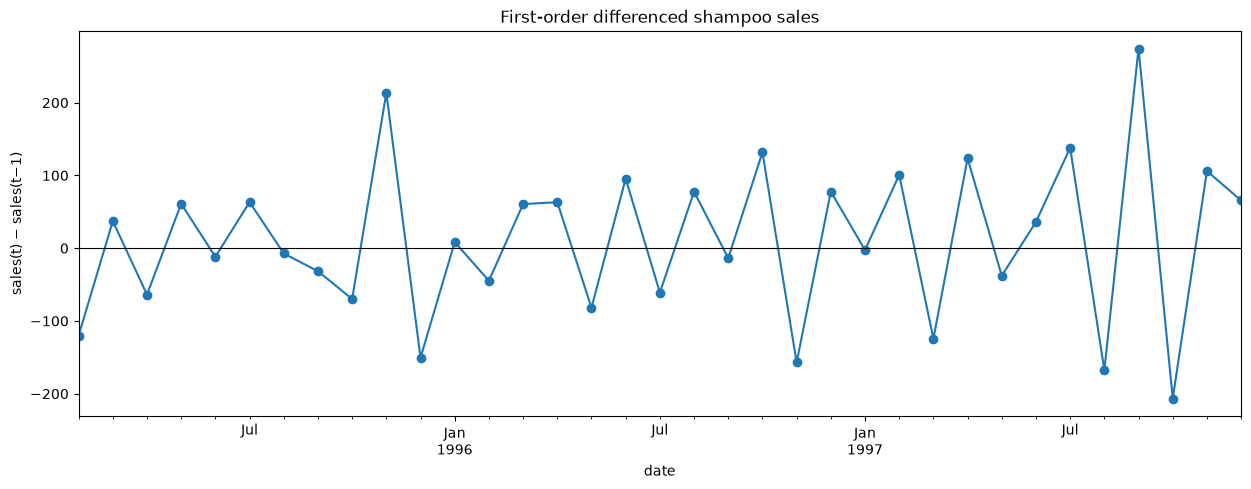

,sales_diff_1
date,
1995-02-01,-120.1
1995-03-01,37.2
1995-04-01,-63.8
1995-05-01,61.0
1995-06-01,-11.8


In [25]:
detrended = difference(sales, lag=1).dropna()   # drop the first NaN (Jan 1995)

df_diff = detrended.to_frame(name="sales_diff_1")

fig, ax = plt.subplots(figsize=(15, 5))
df_diff["sales_diff_1"].plot(ax=ax, marker="o")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("sales(t) − sales(t−1)")
ax.set_title("First-order differenced shampoo sales")
plt.show()

df_diff.head()

**Answer.** First-order differencing removes most of the trend: the series now fluctuates around zero. A small positive drift remains (the yearly mean of the differences goes from ≈ −7 to 13 to 25), which is consistent with an accelerating, roughly quadratic trend. The variance still increases over time (larger swings in 1997), because differencing removes trend but does not stabilize variance. The saw-tooth pattern (alternating signs) points to a strong negative lag-1 autocorrelation.

From the ndiffs function (from pmdarima.arima), estimate the number of differences required to remove the trend


In [26]:
for test in ["kpss", "adf", "pp"]:
    d = ndiffs(sales, alpha=0.05, test=test, max_d=2)
    print(f"{test}: d = {d}")

kpss: d = 1
adf: d = 1
pp: d = 0


**Answer.** KPSS and ADF both suggest **d = 1**, while PP suggests d = 0. Given the obvious upward trend in the raw series, d = 0 is not credible: with only 36 points the tests have low power, and the strong negative autocorrelation likely misleads PP.

A second difference would over-difference the series: its standard deviation rises from 109 to 204 and the lag-1 autocorrelation drops from −0.74 to −0.83. We therefore keep **d = 1**. A lag-1 autocorrelation below −0.5 after one difference also suggests that the series may be closer to "trend + noise" (trend-stationary) than to a random walk.

Check if the ACF plot is changed after differencing. 

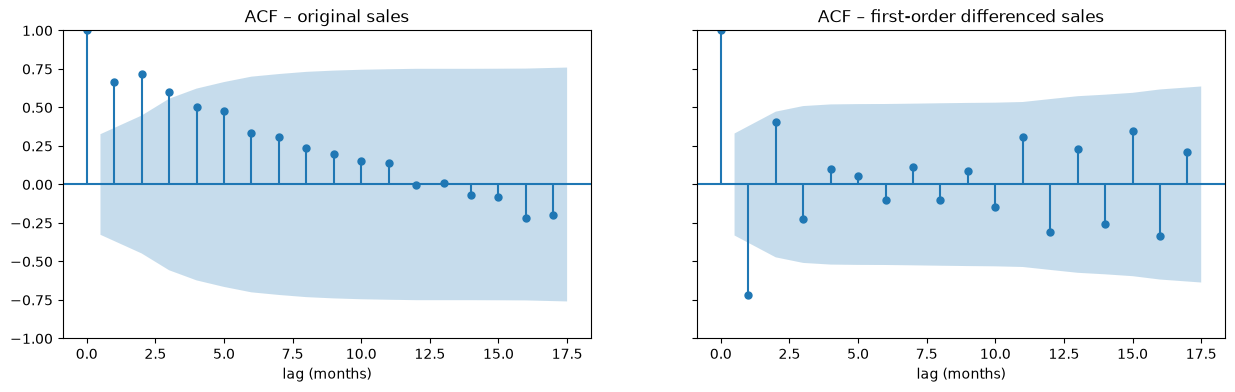

In [27]:
# Compare the ACF of the raw series and of the first-order differenced series.
# 17 lags ≈ half of the 35 differenced points: beyond that, too few pairs remain.
n_lags = 17

fig, axes = plt.subplots(1, 2, figsize=(15, 4), sharey=True)
plot_acf(sales, lags=n_lags, ax=axes[0], title="ACF – original sales")
plot_acf(detrended, lags=n_lags, ax=axes[1], title="ACF – first-order differenced sales")
for ax in axes:
    ax.set_xlabel("lag (months)")
plt.show()

## Synthetized time series

Create a recursive function `rec_difference()` that applies the `difference()` function several times.

Create a time series with a polynomial trend of order 3.
Use the `rec_difference()` function to remove the trend. 

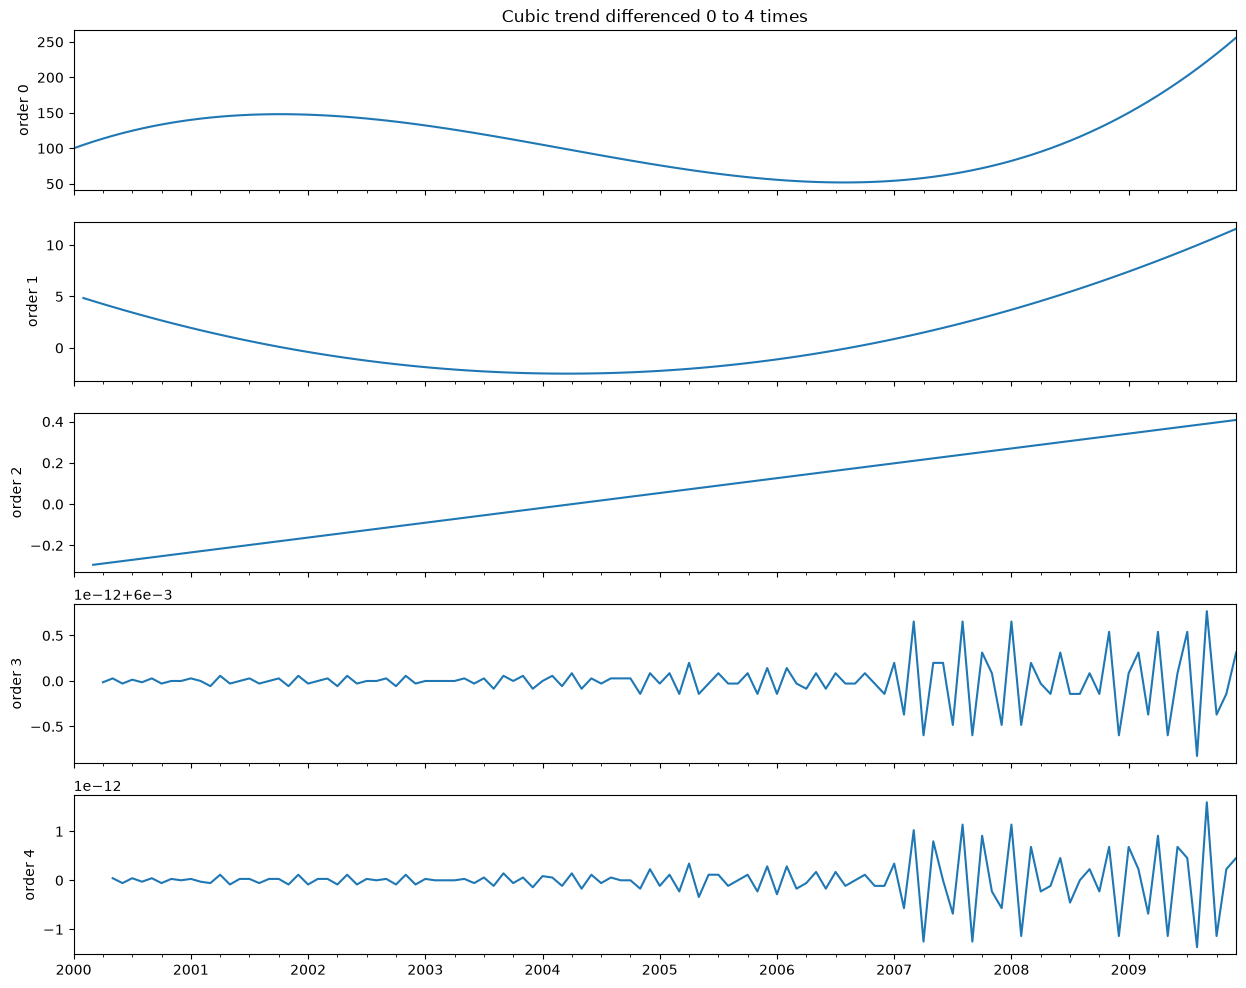

3rd difference: constant = 0.0060 (theory 6a = 0.0060), all equal: True
4th difference: all zero: True


In [28]:
def rec_difference(series: pd.Series, order: int, lag: int = 1) -> pd.Series:
    """Apply ``difference`` recursively ``order`` times.

    Differencing ``order`` times removes a polynomial trend of degree
    ``order``: each pass lowers the polynomial degree by one, so after
    ``order`` passes only a constant remains (and one more pass gives 0).

    Args:
        series: Time series to difference, indexed by time.
        order: Number of times the difference is applied. ``0`` returns the
            series unchanged (base case of the recursion).
        lag: Lag used at every differencing step. Defaults to 1.

    Returns:
        The differenced series, with the same index as ``series``. The first
        ``order * lag`` values are NaN.

    Raises:
        ValueError: If ``order`` is negative.
    """
    if order < 0:
        raise ValueError(f"order must be non-negative, got {order}")
    if order == 0:
        return series
    return rec_difference(difference(series, lag), order - 1, lag)


# Synthetic monthly series (10 years) with a cubic trend:
# trend(t) = a·t³ + b·t² + c·t + d, with local extrema inside the window.
n_months = 120
t = np.arange(n_months)
index = pd.date_range(start="2000-01", periods=n_months, freq="MS")

a, b, c, d = 0.001, -0.15, 5.0, 100.0
cubic_trend = pd.Series(a * t**3 + b * t**2 + c * t + d, index=index, name="cubic")

# Difference 0 to 4 times and plot each result
fig, axes = plt.subplots(5, 1, figsize=(15, 12), sharex=True)
for k, ax in enumerate(axes):
    rec_difference(cubic_trend, order=k).plot(ax=ax)
    ax.set_ylabel(f"order {k}")
axes[0].set_title("Cubic trend differenced 0 to 4 times")
plt.show()

# Theory: the 3rd difference of a·t³ + … is the constant 6·a, and the 4th is 0
third = rec_difference(cubic_trend, order=3).dropna()
fourth = rec_difference(cubic_trend, order=4).dropna()
print(f"3rd difference: constant = {third.iloc[0]:.4f} (theory 6a = {6 * a:.4f}), "
      f"all equal: {np.allclose(third, 6 * a)}")
print(f"4th difference: all zero: {np.allclose(fourth, 0)}")

Add a seasonality to the previous time series. Make sure the `difference()` function removes it. 

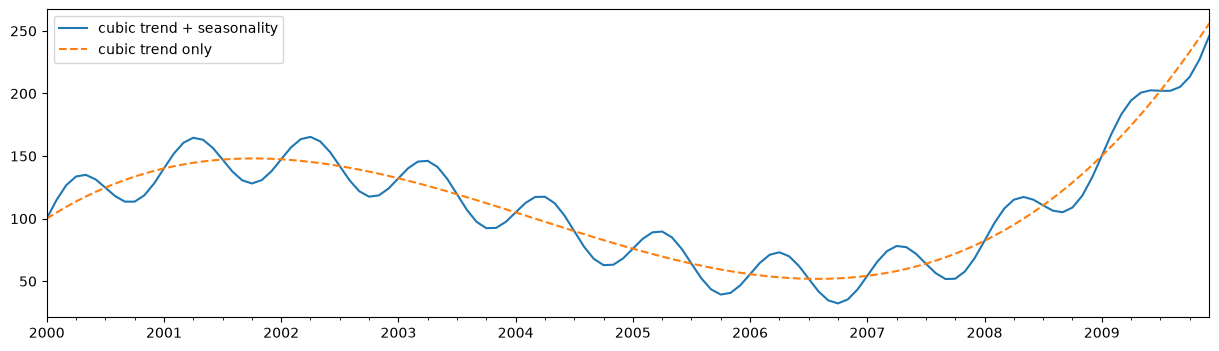

In [29]:
# Add a yearly seasonality (period 12) to the cubic trend
period = 12
amplitude = 20.0
seasonality = pd.Series(amplitude * np.sin(2 * np.pi * t / period), index=index)

seasonal_cubic = cubic_trend + seasonality

fig, ax = plt.subplots(figsize=(15, 4))
seasonal_cubic.plot(ax=ax, label="cubic trend + seasonality")
cubic_trend.plot(ax=ax, style="--", label="cubic trend only")
ax.legend()
plt.show()

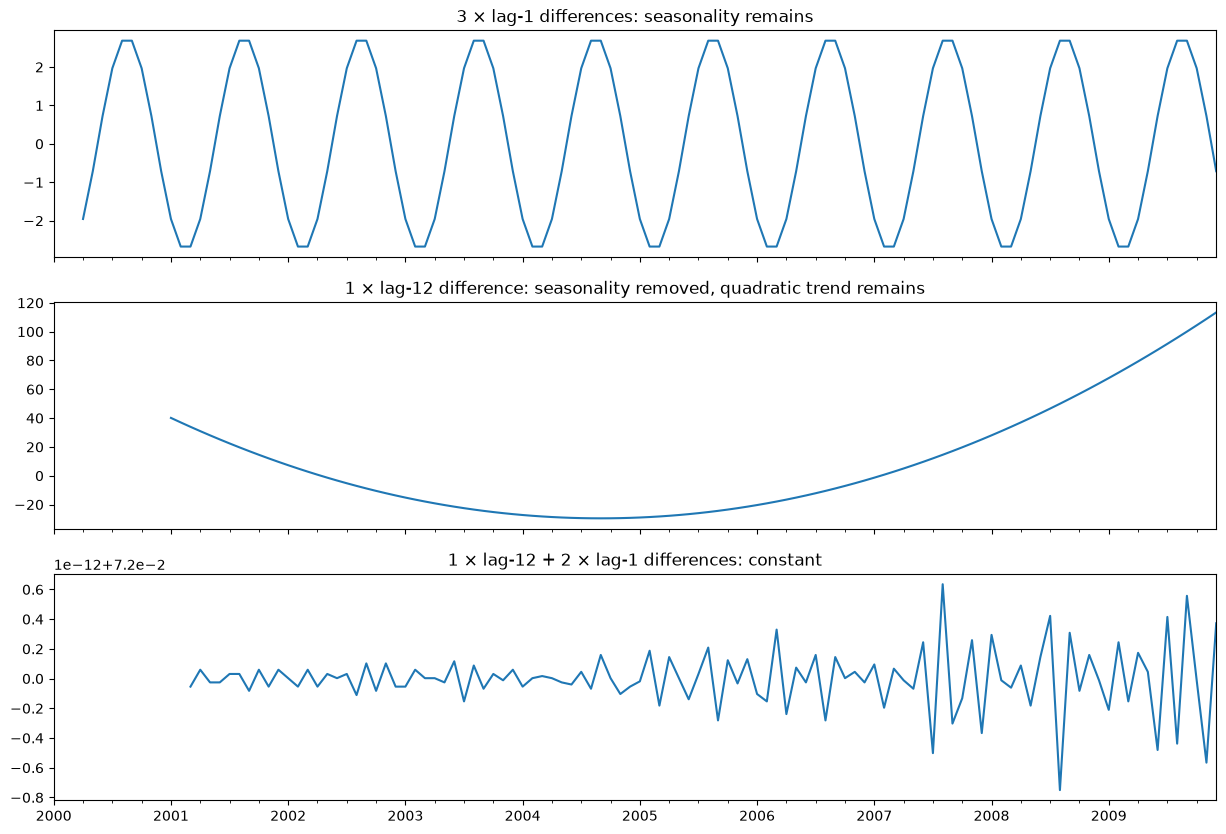

Final series: constant = 0.0720 (theory 72a = 0.0720), all equal: True


In [30]:
# (1) Lag-1 differences only: the trend goes away, but the seasonality does not,
#     because the difference of a sine is another sine with the same period.
lag1_only = rec_difference(seasonal_cubic, order=3, lag=1)

# (2) One seasonal difference (lag 12) removes the seasonality exactly, since
#     s(t) = s(t - 12). It also lowers the trend degree by one (cubic -> quadratic),
#     so two lag-1 differences are enough to finish removing the trend.
seasonal_diff = difference(seasonal_cubic, lag=period)
fully_cleaned = rec_difference(seasonal_diff, order=2, lag=1)

fig, axes = plt.subplots(3, 1, figsize=(15, 10), sharex=True)
lag1_only.plot(ax=axes[0], title="3 × lag-1 differences: seasonality remains")
seasonal_diff.plot(ax=axes[1], title="1 × lag-12 difference: seasonality removed, quadratic trend remains")
fully_cleaned.plot(ax=axes[2], title="1 × lag-12 + 2 × lag-1 differences: constant")
plt.show()

# Theory: Δ₁₂ Δ₁ Δ₁ (a·t³) = 6 · a · 12 · 1 · 1 = 72a, and the sine cancels out
cleaned = fully_cleaned.dropna()
print(f"Final series: constant = {cleaned.iloc[0]:.4f} (theory 72a = {72 * a:.4f}), "
      f"all equal: {np.allclose(cleaned, 72 * a)}")

---------------
---------------
This notebook is freely inspired from:
- https://machinelearningmastery.com/remove-trends-seasonality-difference-transform-python/